# The Distribution of U.S. Firm Revenue

In [a previous example](https://allendowney.github.io/ProbablyOverthinkingIt/firm_size.html), I fit several models to the distribution of firm sizes measured by number of employees, using COMPUSTAT data.
And in [another example](https://allendowney.github.io/ProbablyOverthinkingIt/firm_size_france.html), I fit the same models to the distribution of revenue for French companies.

In this example, I'll use the same COMPUSTAT data, but measure firm size by revenue, and fit the same models in the same way.

[Click here to run this notebook on Colab](https://colab.research.google.com/github/AllenDowney/ProbablyOverthinkingIt/blob/book/examples/firm_size_revenue.ipynb).

In [1]:
# Install empiricaldist if we don't already have it

try:
    import empiricaldist
except ImportError:
    !pip install empiricaldist

In [2]:
# download utils.py and tail_models.py

from os.path import basename, exists


def download(url):
    filename = basename(url)
    if not exists(filename):
        from urllib.request import urlretrieve

        local, _ = urlretrieve(url, filename)
        print("Downloaded " + local)


download(
    "https://github.com/AllenDowney/ProbablyOverthinkingIt/raw/book/notebooks/utils.py"
)
download(
    "https://github.com/AllenDowney/ProbablyOverthinkingIt/raw/book/examples/tail_models.py"
)

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from empiricaldist import Cdf, TailDist
from utils import decorate, set_pyplot_params

set_pyplot_params()

## Data

Bloom, Nicholas, Jones, Charles I., Van Reenen, John, and Webb, Michael.
Data and Code for: Are Ideas Getting Harder to Find?: Compustat: Compustat WRDS 2016 06 13.csv.
Nashville, TN: American Economic Association [publisher], 2020.
Ann Arbor, MI: Inter-university Consortium for Political and Social Research [distributor], 2020-03-30.
[https://doi.org/10.3886/E111743V2-209061](https://doi.org/10.3886/E111743V2-209061)

The extract is distributed with the openICPSR replication archive under [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/), so we can redistribute it here.
Individual firms count as research subjects under ICPSR rules, so we report only aggregate distributional results and do not identify particular companies.

In [4]:
DATA_FILE = "Compustat-WRDS-2016-06-13.csv"
download(
    "https://github.com/AllenDowney/ProbablyOverthinkingIt/raw/book/data/" + DATA_FILE
)

raw = pd.read_csv(DATA_FILE)
raw.shape

(516350, 23)

COMPUSTAT reports two measures of revenue, `sale` and `revt`.
Where both are reported, they are the same, but `revt` is available for more firms, so I'll use it.
Revenue is reported in millions, in the currency the firm reports in, which is either U.S. or Canadian dollars.

In [5]:
year = 2014
df = raw.loc[(raw["fyear"] == year) & (raw["revt"] > 0), ["fyear", "revt", "curcd"]].copy()
df["curcd"].value_counts()

curcd
USD    7584
CAD    1113
Name: count, dtype: int64

To convert Canadian dollars to U.S. dollars, I'll use the annual average exchange rate from the Federal Reserve ([H.10](https://www.federalreserve.gov/releases/h10/), FRED series [AEXCAUS](https://fred.stlouisfed.org/series/AEXCAUS)), which is the number of Canadian dollars per U.S. dollar.
I use the rate for the calendar year that matches the fiscal year, so for firms whose fiscal year ends early in the calendar year, the conversion is approximate.

In [6]:
FX_FILE = "fred_aexcaus.csv"
download(
    "https://github.com/AllenDowney/ProbablyOverthinkingIt/raw/book/data/" + FX_FILE
)

fx = pd.read_csv(FX_FILE, parse_dates=["observation_date"])
cad_per_usd = pd.Series(fx["AEXCAUS"].values, index=fx["observation_date"].dt.year)
cad_per_usd.loc[2005:2014]

observation_date
2005    1.2115
2006    1.1340
2007    1.0734
2008    1.0660
2009    1.1412
2010    1.0298
2011    0.9887
2012    0.9995
2013    1.0300
2014    1.1043
dtype: float64

The following function converts revenue to U.S. dollars.

In [7]:
def revenue_usd(frame):
    """Revenue in U.S. dollars.

    frame: DataFrame with columns fyear, revt (millions), and curcd

    returns: Series
    """
    rate = frame["fyear"].map(cad_per_usd).where(frame["curcd"] == "CAD", 1.0)
    return frame["revt"] * 1e6 / rate

In [8]:
revenue = revenue_usd(df)
n = len(revenue)
revenue.describe()

count    8.697000e+03
mean     3.849256e+09
std      1.711566e+10
min      9.055510e+02
25%      3.069000e+07
50%      2.302250e+08
75%      1.433400e+09
max      4.835210e+11
dtype: float64

As with employment, the mean is far above what we would expect for all U.S. firms, because COMPUSTAT is dominated by large, mostly publicly traded companies.

## Distribution of revenue

Here is the CDF of revenue on a log-$x$ scale.

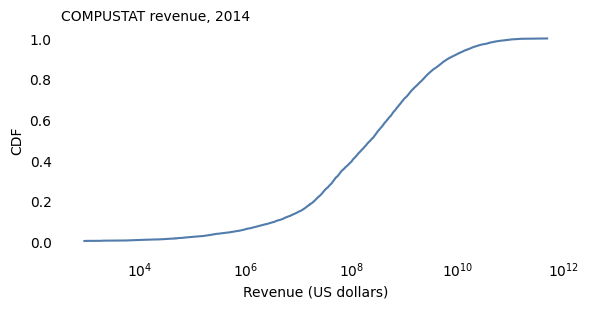

In [9]:
Cdf.from_seq(revenue).plot()

decorate(xlabel="Revenue (US dollars)", ylabel="CDF", xscale="log",
         title=f"COMPUSTAT revenue, {year}")

On a log scale, the CDF has roughly the sigmoid shape of a normal distribution, so the lognormal model is a natural candidate.

## Log revenue

As in the other examples, I'll work with the logarithm of revenue, base 10.

In [10]:
mags = np.log10(revenue)
mags.describe()

count    8697.000000
mean        8.252025
std         1.314951
min         2.956913
25%         7.486997
50%         8.362152
75%         9.156367
max        11.684415
dtype: float64

In [11]:
tail_log = TailDist.from_seq(mags)

In [12]:
xlabel_log = "Revenue (log10 US dollars)"
ylabel = "Prob >= $x$"

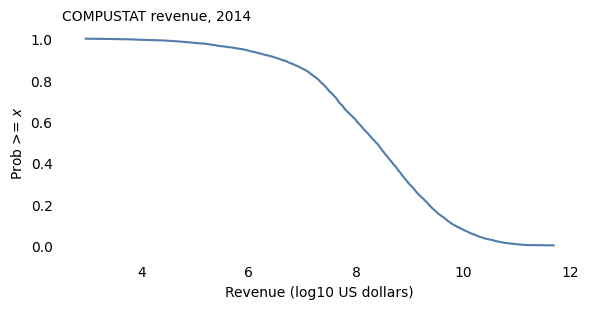

In [13]:
tail_log.plot()

decorate(xlabel=xlabel_log, ylabel=ylabel, title=f"COMPUSTAT revenue, {year}")

## Fitting truncated models

As in the employment example, I'll treat the smallest value in the sample as a cutoff and truncate each model there, and fit the models using functions in [`tail_models.py`](https://github.com/AllenDowney/ProbablyOverthinkingIt/blob/book/examples/tail_models.py):

* Location and scale are chosen to match percentiles of the data (`fit_loc_scale`).
* A shape parameter, if the model has one, is chosen to match the largest values -- it minimizes the squared differences between the logarithms of the tail probabilities, from 1% down to the second-largest value (`fit_shape`).

`plot_two` shows the data and a model on a linear-$y$ scale and a log-$y$ scale; on the log-$y$ scale, the shaded area shows how much variation we would expect due to sampling if the model were correct.
`model_errors` computes the mean absolute difference between the tail distributions on the linear scale and the root mean squared difference between log tail probabilities.

In [14]:
from tail_models import (
    truncated_tail,
    fit_loc_scale,
    fit_shape,
    pareto2_tail,
    fit_pareto2_scale,
    fit_pareto2_alpha,
    plot_two,
    model_errors,
    fit_models,
    YTICKS_LOG,
)

In [15]:
low, high = tail_log.qs.min(), tail_log.qs.max()
qs = np.linspace(low, high + 0.5, 2000)
log_cutoff = low

In [16]:
results = {}

## Lognormal model

In [17]:
from scipy.stats import norm

mu, sigma = fit_loc_scale(norm, tail_log, ps=np.linspace(0.1, 0.99, 20))
mu, sigma

(8.327402224696566, 1.2465792684700328)

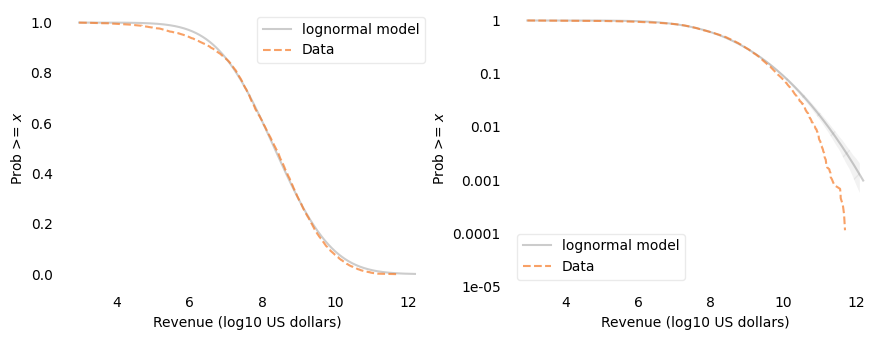

In [18]:
tail_lognormal = truncated_tail(norm, qs, mu, sigma)
plot_two(tail_log, tail_lognormal, n, "lognormal model", xlabel_log)

On the linear-$y$ scale, the lognormal model fits well above about \$10 million; below that, the data are below the model, which means there are more firms with very small revenue than the model predicts.
On the log-$y$ scale, above about \$10 billion, the data fall below the model, and for the largest firms the discrepancy is up to an order of magnitude -- well outside the range we would expect from random sampling.
As with employment, the largest firms are less common than the lognormal model predicts.

In [19]:
results["lognormal"] = model_errors(tail_log, tail_lognormal)
results["lognormal"]

(0.008493945798591708, 0.5401525224853155)

## Log-Student-$t$ model

The Student-$t$ distribution has a parameter, `df`, that controls the thickness of the tails; a log-Student-$t$ model can only have thicker tails than the lognormal model.

In [20]:
from scipy.stats import t as t_dist

df_t = fit_shape(t_dist, tail_log, shape0=10, bounds=(1, 1000))
df_t

999.9993027032061

In [21]:
mu_t, sigma_t = fit_loc_scale(t_dist, tail_log, shape=(df_t,))
mu_t, sigma_t

(8.327788809477802, 1.2411318557168631)

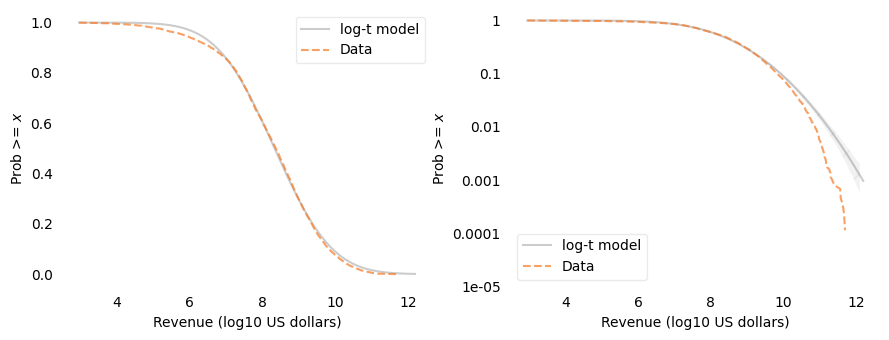

In [22]:
tail_t = truncated_tail(t_dist, qs, df_t, mu_t, sigma_t)
plot_two(tail_log, tail_t, n, "log-t model", xlabel_log)

As with employment, the fitted value of `df` is at the upper bound of the search, 1000, so the best log-$t$ model is indistinguishable from the lognormal model: these data need thinner tails, not thicker ones.

In [23]:
results["log-t"] = model_errors(tail_log, tail_t)
results["log-t"]

(0.008429556782407274, 0.5352198028520144)

## Log-generalized-normal model

The generalized normal distribution has a shape parameter, $\beta$: $\beta = 2$ is the normal distribution, $\beta < 2$ has thicker tails, and $\beta > 2$ has thinner tails.

In [24]:
from scipy.stats import gennorm

beta = fit_shape(gennorm, tail_log, shape0=2, bounds=(0.5, 20))
beta

2.8911929751088166

In [25]:
mu_g, alpha_g = fit_loc_scale(gennorm, tail_log, shape=(beta,))
mu_g, alpha_g

(8.3254550915095, 1.8643986717383727)

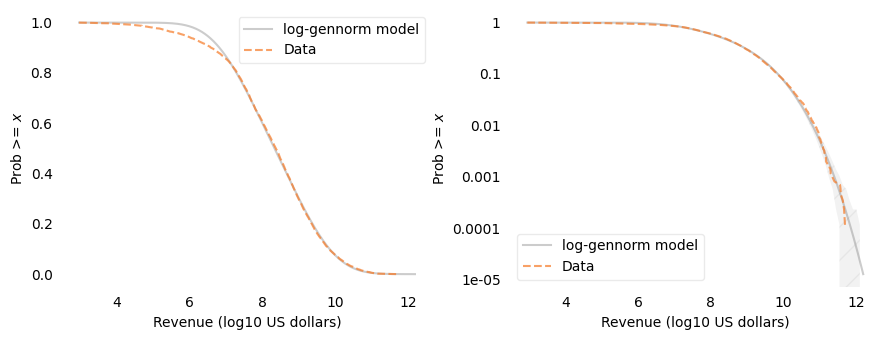

In [26]:
tail_gennorm = truncated_tail(gennorm, qs, beta, mu_g, alpha_g)
plot_two(tail_log, tail_gennorm, n, "log-gennorm model", xlabel_log)

The fitted value of $\beta$ is about 2.9, greater than 2, so the departure from the lognormal model is toward thinner tails.
On the log-$y$ scale, the log-generalized-normal model fits well, with the data within the range we would expect from random sampling.
On the linear-$y$ scale, it has the same discrepancy below \$10 million as the lognormal model.

In [27]:
results["log-gennorm"] = model_errors(tail_log, tail_gennorm)
results["log-gennorm"]

(0.00853412336377755, 0.06402911040379779)

## Pareto model

As in the other examples, I'll use a Pareto II (Lomax) distribution, which has an exponent, $\alpha$, and a scale parameter, $s$:

$$P(X \ge x ~|~ X \ge c) = \left(1 + \frac{x - c}{s}\right)^{-\alpha}$$

where $c$ is the cutoff.
`fit_pareto2_alpha` chooses $\alpha$ to match the largest values, and `fit_pareto2_scale` chooses the scale to match percentiles.

In [28]:
alpha = fit_pareto2_alpha(tail_log, log_cutoff)
alpha

0.8854771654818054

In [29]:
log_scale = fit_pareto2_scale(tail_log, alpha, log_cutoff)
log_scale, 10**log_scale

(8.263355922375098, 183381669.56860912)

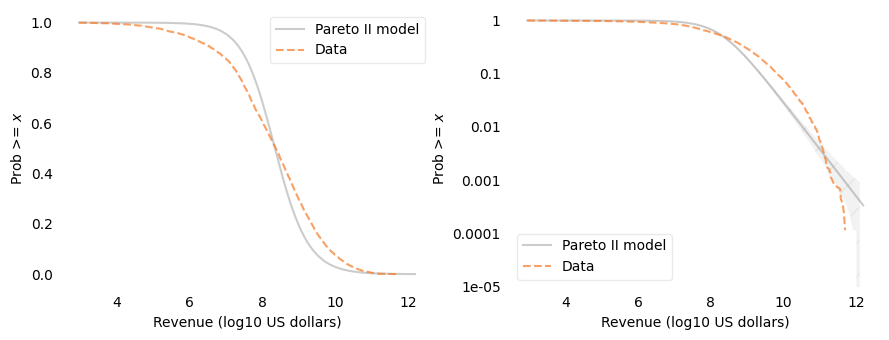

In [30]:
tail_pareto = pareto2_tail(qs, alpha, log_scale, log_cutoff)
plot_two(tail_log, tail_pareto, n, "Pareto II model", xlabel_log)

The fitted exponent is about 0.89, and the scale is about \$180 million.
The Pareto II model does not fit this distribution: on the linear-$y$ scale it is visibly off over most of the range, and on the log-$y$ scale it is below the data between about \$100 million and \$100 billion and above the data for the largest firms.

In [31]:
results["Pareto II"] = model_errors(tail_log, tail_pareto)
results["Pareto II"]

(0.07630993168613927, 0.31305324509418075)

## Comparison

Here are all four models on a log-$y$ scale.

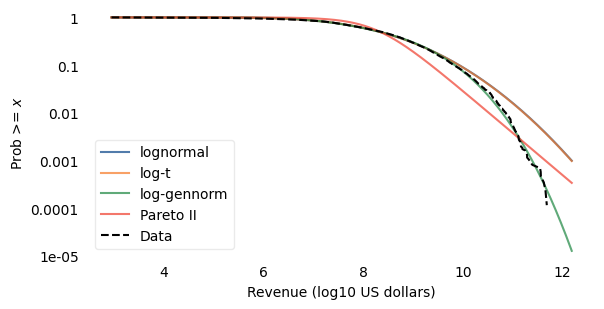

In [32]:
tail_lognormal.plot(label="lognormal")
tail_t.plot(label="log-t")
tail_gennorm.plot(label="log-gennorm")
tail_pareto.plot(label="Pareto II")
tail_log.plot(color="black", ls="--", label="Data")

decorate(xlabel=xlabel_log, ylabel=ylabel, yscale="log", ylim=[1e-5, 1.5])
plt.yticks(YTICKS_LOG, YTICKS_LOG);

And here are the errors.

In [33]:
pd.DataFrame(results, index=["Mean abs error", "RMS log error"]).T.round(4)

,Mean abs error,RMS log error
lognormal,0.0085,0.5402
log-t,0.0084,0.5352
log-gennorm,0.0085,0.0640
Pareto II,0.0763,0.3131


The lognormal and log-$t$ curves are nearly the same.
On the linear scale, the lognormal, log-$t$, and log-generalized-normal models have about the same error; the Pareto II model's error is about nine times larger.
On the log scale, the log-generalized-normal model has the smallest error by a wide margin.

## Robustness

To see whether these results depend on the year or the cutoff, I'll fit the lognormal, log-generalized-normal, and Pareto II models for each fiscal year from 2005 through 2014, and for several cutoffs.
The following function selects the data, converting Canadian dollars at the rate for each year.

In [34]:
def select_revenue(raw, year, cutoff):
    """Select log revenue (US dollars) at or above the cutoff for one fiscal year."""
    frame = raw.loc[(raw["fyear"] == year) & (raw["revt"] > 0)]
    revenue = revenue_usd(frame)
    return np.log10(revenue[revenue >= cutoff])

Here are the results for each year, using all firms with positive revenue.
With no cutoff argument, `fit_models` uses the smallest value as the cutoff.

In [35]:
rows = {y: fit_models(select_revenue(raw, y, 0)) for y in range(2005, 2015)}
by_year = pd.DataFrame(rows).T
by_year.round(3)

,n,beta,alpha,log_scale,rmse_lognormal,rmse_gennorm,rmse_pareto
2005,10194.0,2.409,0.895,8.076,0.342,0.094,0.314
2006,9924.0,2.409,0.888,8.117,0.349,0.115,0.322
2007,9454.0,2.421,0.877,8.147,0.355,0.135,0.331
2008,9180.0,2.394,0.883,8.179,0.327,0.099,0.308
2009,9040.0,2.413,0.884,8.146,0.354,0.157,0.341
2010,8918.0,2.445,0.877,8.180,0.366,0.131,0.329
2011,8814.0,2.515,0.870,8.207,0.386,0.098,0.313
2012,9107.0,2.665,0.854,8.153,0.466,0.081,0.318
2013,9101.0,2.761,0.857,8.168,0.498,0.072,0.318
2014,8697.0,2.891,0.885,8.263,0.540,0.064,0.313


In every year from 2005 through 2014, the log-generalized-normal model fits best on the log scale, with $\beta$ between 2.4 and 2.9 -- always thinner-tailed than the lognormal model.
The fitted value of $\beta$ increases after 2010.
The lognormal and Pareto II models fit substantially worse in every year, and the Pareto exponent is between 0.85 and 0.90.

And here are the results for fiscal year 2014 with several cutoffs.

In [36]:
cutoffs = [1e6, 1e7, 1e8, 1e9]
rows = {f"${c:,.0f}": fit_models(select_revenue(raw, year, c), np.log10(c)) for c in cutoffs}
by_cutoff = pd.DataFrame(rows).T
by_cutoff.round(3)

,n,beta,alpha,log_scale,rmse_lognormal,rmse_gennorm,rmse_pareto
"$1,000,000",8190.0,2.645,0.916,8.378,0.458,0.073,0.300
"$10,000,000",7433.0,2.663,0.966,8.544,0.480,0.070,0.282
"$100,000,000",5266.0,2.646,1.111,8.999,0.301,0.072,0.228
"$1,000,000,000",2569.0,19.999,1.366,9.623,0.323,0.171,0.154


With cutoffs of \$1 million, \$10 million, and \$100 million, the results hardly change: $\beta$ is about 2.65 and the log-generalized-normal model fits well.
So the discrepancy among the smallest firms doesn't affect the fitted shape.

With the \$1 billion cutoff, $\beta$ reaches the upper bound of the search, 20, so that fit is not meaningful.
The Pareto II exponent increases with the cutoff, from about 0.92 to about 1.37, and with the \$1 billion cutoff the Pareto II model fits a little better than the others -- but among these roughly 2,600 firms, none of the models fits as well as the log-generalized-normal model does for the whole sample.

## Summary

* For COMPUSTAT revenue in 2014, the lognormal model fits most of the distribution, but the largest firms are less common than it predicts -- the same pattern as for employment.

* A log-Student-$t$ model can't help, because it can only make the tails thicker.

* A log-generalized-normal model with $\beta$ about 2.9 fits the upper part of the distribution well, and it fits best on the log scale in every year from 2005 through 2014, with $\beta$ between 2.4 and 2.9. The fitted shape is about the same for cutoffs from \$1 million to \$100 million.

* A Pareto II model does not fit the whole sample; above \$1 billion it does a little better than the others, with exponent about 1.4.

Copyright 2026 Allen B. Downey

Example related to Chapters 4 and 8 from [Probably Overthinking It](https://allendowney.github.io/ProbablyOverthinkingIt/).

License: [Attribution-NonCommercial-ShareAlike 4.0 International (CC BY-NC-SA 4.0)](https://creativecommons.org/licenses/by-nc-sa/4.0/)